# BCR из парных FASTQ образца DChu_T7_pbmc_d7COVID2_2

Исследуем состав тяжёлых цепей иммуноглобулина (IGH) в одной библиотеке PBMC. Какую часть прочтений удалось собрать, какие изотипы представлены и сколько молекулярных наблюдений приходится на частые клонотипы? Единицей анализа служит клонотип MiXCR, собранный по области от начала CDR1 до конца FR4 с разделением по C-гену. Измерение по РНК может придавать больший вес клеткам с высокой экспрессией иммуноглобулина.

In [1]:
from pathlib import Path
from collections import Counter
from itertools import zip_longest
import gzip
import json
import shutil
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from repseq import stats

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'environment.yml').is_file())
out = root / 'outputs' / 'bcr'
out.mkdir(parents=True, exist_ok=True)
sample = 'DChu_T7_pbmc_d7COVID2_2'
r1, r2 = [root / f'{sample}_R{mate}.fastq.gz' for mate in [1, 2]]
prefix = out / sample

## Проверка пары и выбор протокола

Проверяем соответствие идентификаторов R1 и R2 во всей библиотеке. В R1 ищем точное совпадение с якорем из пресета при сдвиге 0–2. Это независимая проверка структуры до выравнивания. Для обработки используем штатный пресет `milab-human-rna-ig-umi-multiplex` в MiXCR 4.7.0. Он извлекает 14-нуклеотидную UMI, выравнивает последовательности на человеческие V/D/J/C, корректирует метки и собирает клонотипы. Параметры тримминга берутся из установленной версии пресета. [Протокол MiLaboratories](https://mixcr.com/mixcr/guides/milaboratories-human-bcr-rna-multi/)

In [2]:
def reads(path):
    with gzip.open(path, 'rb') as fastq:
        for header in fastq:
            sequence = fastq.readline().rstrip()
            separator = fastq.readline()
            quality = fastq.readline().rstrip()
            if not header.startswith(b'@') or not separator.startswith(b'+') or len(sequence) != len(quality):
                raise ValueError(f'Повреждена запись в {path.name}')
            yield header.split()[0], sequence

anchor = b'TGGTATCAACGCAGAGT'
offsets, lengths = Counter(), Counter()
for left, right in zip_longest(reads(r1), reads(r2)):
    if left is None or right is None or left[0] != right[0]:
        raise ValueError('Нарушено соответствие R1 и R2')
    lengths[len(left[1]), len(right[1])] += 1
    offsets[left[1].find(anchor, 0, len(anchor) + 2)] += 1
total = sum(lengths.values())
print(f'Прочитано пар: {total:,}. Длины (R1, R2): {dict(lengths)}.')
print(f'Точный якорь R1 на позициях 0–2: {total-offsets[-1]:,} пар ({1-offsets[-1]/total:.2%}).')

Прочитано пар: 938,889. Длины (R1, R2): {(251, 251): 938889}.
Точный якорь R1 на позициях 0–2: 899,815 пар (95.84%).


## Сборка с MiXCR

При наличии экспорта ячейка читает результат выполненного запуска. На чистом каталоге запускает тот же конвейер от обоих исходных FASTQ. Для нового запуска требуется активированная лицензия MiXCR. JSON- и текстовые отчёты по каждому этапу находятся рядом с клоносетом.

In [3]:
preset = 'milab-human-rna-ig-umi-multiplex'
clone_file = out / f'{sample}.clones_IGH.tsv'
if not clone_file.is_file():
    mixcr = shutil.which('mixcr') or str(Path(sys.prefix) / 'bin' / 'mixcr')
    subprocess.run([mixcr, '-Xmx4g', 'analyze', preset, '-t', '4',
                    str(r1), str(r2), str(prefix)], check=True)
clones = pd.read_csv(clone_file, sep='\t', keep_default_na=False)
print(f'Строк в экспорте IGH: {len(clones):,}')

Строк в экспорте IGH: 37,516


## Сколько материала сохранилось на каждом этапе

Для долей прочтений знаменатель — все входные пары. Для фильтра UMI отдельно указываем число групп после коррекции и число групп, прошедших порог. Одна UMI-группа может объединять несколько копий исходной молекулы.

In [4]:
def report(stage):
    return json.loads((out / f'{sample}.{stage}.report.json').read_text())

align, refine, assemble = (report(stage) for stage in ['align','refine','assemble'])
filt = refine['correctionReport']['filterReport']
print('MiXCR', align['version'])
assert align['totalReadsProcessed'] == total
assert align['chainUsage']['chains']['IGH']['total'] == align['aligned']
assert len(clones) == assemble['clones'] and clones.readCount.sum() == assemble['readsInClones']
pairs_qc = pd.Series({
    'Прочитаны': total,
    'Распознан рисунок меток': align['tagParsingReport']['matched'],
    'Выровнены на IGH': align['aligned'],
    'Покрывают CDR3': align['coverage']['CDR3'],
    'Сохранены после фильтра UMI': int(filt['totalWeightAccepted']),
    'Представлены в экспортированных IGH-клонотипах': int(clones.readCount.sum())
}, name='Пары')
display(pairs_qc.to_frame().assign(процент_от_входа=(100*pairs_qc/total).round(2)))
print('Группы UMI после коррекции:', filt['numberOfGroups'],
      '· прошли фильтр:', filt['numberOfGroupsAccepted'],
      '· порог прочтений:', filt['operatorReports'][0]['operatorReport']['threshold'])
print('Основные причины потерь при выравнивании (пар):',
      sorted(align['notAlignedReasons'].items(), key=lambda x: -x[1])[:3])
print((out / f'{sample}.qc.txt').read_text().strip())

MiXCR 4.7.0; built=Wed Aug 07 22:19:48 MSK 2024; rev=976ba14139; lib=repseqio.v5.1


,Пары,процент_от_входа
Прочитаны,938889,100.00
Распознан рисунок меток,935789,99.67
Выровнены на IGH,865681,92.20
Покрывают CDR3,858554,91.44
Сохранены после фильтра UMI,782678,83.36
Представлены в экспортированных IGH-клонотипах,716879,76.35


Группы UMI после коррекции: 163191 · прошли фильтр: 103842 · порог прочтений: 3.0
Основные причины потерь при выравнивании (пар): [('NoJHits', 49370), ('NoHits', 8994), ('VAndJOnDifferentTargets', 6672)]
Successfully aligned reads:                           92.2%  [OK]
  Off target (non TCR/IG) reads:                        0.96%  [OK]
  Reads with no V or J hits:                            5.32%  [OK]
  Reads with no barcode:                                0.33%  [OK]
  Overlapped paired-end reads:                          93.92% [OK]
  Alignments that do not cover CDR1_TO_FR4:             2.84%  [OK]
  Tag groups that do not cover CDR1_TO_FR4:             0.12%  [OK]
  Barcode collisions in clonotype assembly:             2.73%  [WARN]
  Unassigned alignments in clonotype assembly:          1.67%  [OK]
  Reads used in clonotypes:                             91.59% [OK]
  Alignments dropped due to low sequence quality:       0.0%   [OK]
  Clones dropped in post-filtering:             

## Состав репертуара IGH

Используем тот же критерий функциональности CDR3, что и в T-клеточной работе. Оставляем строки с переведённой CDR3 без стоп-кодона и символа сдвига рамки. Он характеризует участок CDR3. Частоты рассчитываем по числу UMI, отнесённых к клонотипу. Для V и J берём первый назначенный ген, для изотипа — аннотацию MiXCR.

In [5]:
umi_field = 'uniqueMoleculeCount'
valid = clones.aaSeqCDR3.ne('') & ~clones.aaSeqCDR3.str.contains(r'[*_]') & ~clones.nSeqCDR3.str.contains('region_not_covered', case=False)
h = clones.loc[valid].copy()
h['umi'] = pd.to_numeric(h[umi_field], errors='raise').astype(int)
assert h.umi.gt(0).all() and h.cloneId.is_unique
h['frequency'] = h.umi / h.umi.sum()
h['length'] = h.aaSeqCDR3.str.len()
for gene in ['V','J']:
    h[gene] = h[f'all{gene}HitsWithScore'].str.split(r'[,*(]', regex=True).str[0].replace('', 'Без назначения')
h['isotype'] = h.isotype.replace('', 'Без назначения')
counts = h.umi.to_numpy()
p = h.frequency.to_numpy()
summary = pd.Series({
    'Клонотипы IGH в экспорте': len(clones),
    'Клонотипы после фильтра CDR3': len(h),
    'UMI в экспорте IGH': pd.to_numeric(clones[umi_field]).sum(),
    'UMI после фильтра CDR3': counts.sum(),
    'Уникальные CDR3aa после фильтра': h.aaSeqCDR3.nunique(),
    'Клонотипы с одной UMI, % строк': 100 * (counts == 1).mean(),
    'Доля крупнейшего клонотипа, % UMI': 100*p.max(),
    'Доля первых 10 клонотипов, % UMI': 100*h.frequency.nlargest(10).sum(),
    'Индекс Шеннона, натуральный логарифм': -np.sum(p*np.log(p)),
    'Обратный индекс Симпсона': 1/np.sum(p*p),
    'Средняя длина CDR3, аминокислоты (вес UMI)': np.average(h.length, weights=counts),
    'Конвергенция CDR3nt/CDR3aa': h.nSeqCDR3.nunique()/h.aaSeqCDR3.nunique()
}, name='Значение')
summary.to_csv(out / 'igh_summary.csv')
display(summary.to_frame().round(3))
isotypes = h.groupby('isotype').agg(clonotypes=('cloneId','size'), umi=('umi','sum')).sort_values('umi', ascending=False)
isotypes['pct_umi'] = 100 * isotypes.umi / counts.sum()
isotypes['pct_clonotypes'] = 100 * isotypes.clonotypes / len(h)
isotypes.to_csv(out / 'igh_isotypes.csv')
display(isotypes.round(2))

,Значение
Клонотипы IGH в экспорте,37516.000
Клонотипы после фильтра CDR3,36416.000
UMI в экспорте IGH,90924.000
UMI после фильтра CDR3,89665.000
Уникальные CDR3aa после фильтра,29367.000
"Клонотипы с одной UMI, % строк",67.177
"Доля крупнейшего клонотипа, % UMI",0.719
"Доля первых 10 клонотипов, % UMI",3.864
"Индекс Шеннона, натуральный логарифм",9.326
Обратный индекс Симпсона,1994.659


,clonotypes,umi,pct_umi,pct_clonotypes
isotype,,,,
IgM,19308,36711,40.94,53.02
IgD,14637,19335,21.56,40.19
IgG1,1171,16683,18.61,3.22
IgA1,830,10279,11.46,2.28
IgG3,138,2925,3.26,0.38
IgA2,187,2434,2.71,0.51
IgG2,136,1277,1.42,0.37
IgG4,3,15,0.02,0.01
Без назначения,5,5,0.01,0.01


## Длины CDR3, V/J, частые клонотипы и глубина

По оси частот доли нормированы внутри отфильтрованного IGH-репертуара. Кривая разрежения показывает среднее обнаруженное богатство по трём воспроизводимым подвыборкам UMI без возвращения. Её конечная точка соответствует всем молекулярным наблюдениям, включённым в этот анализ.

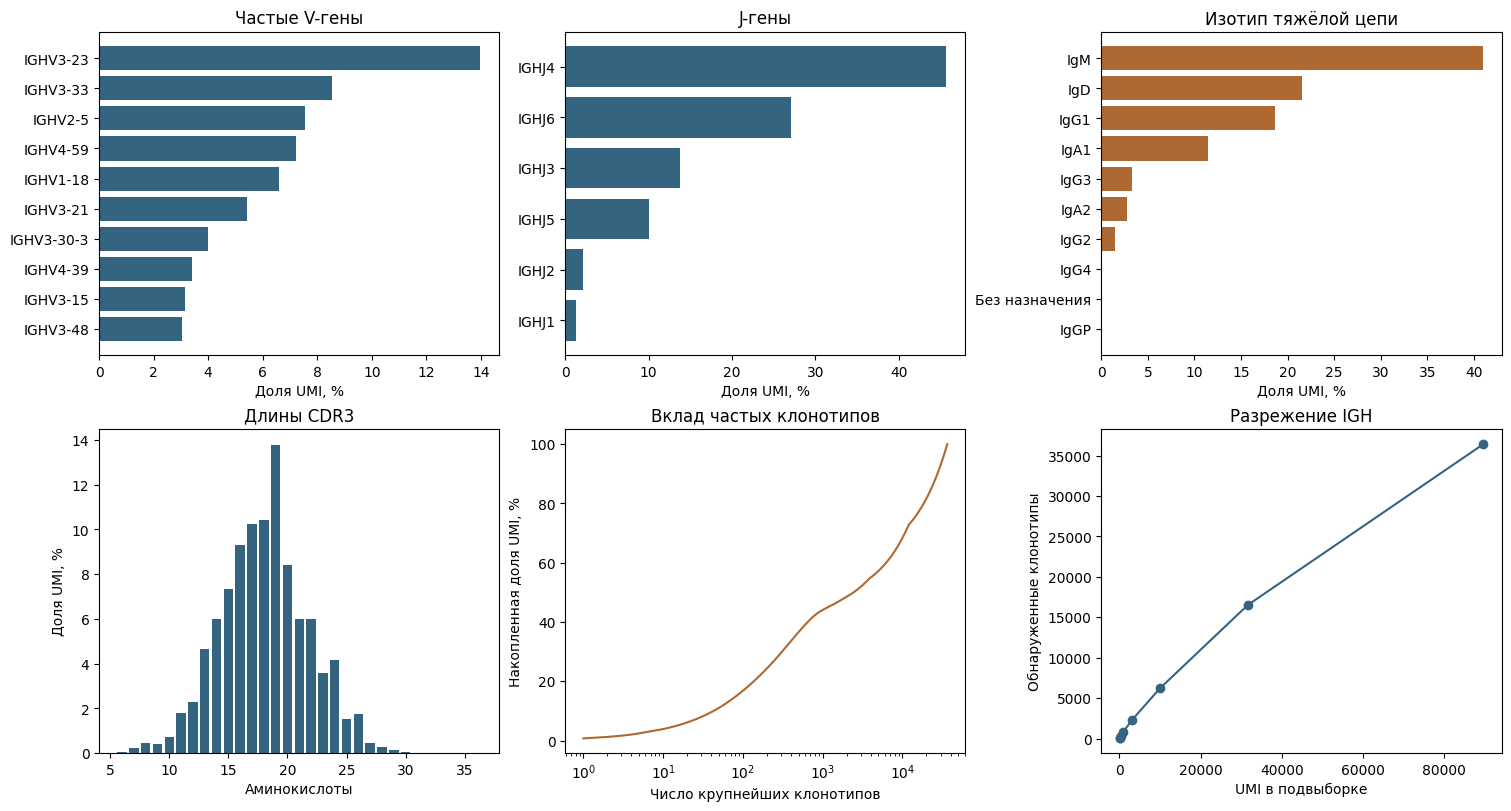

,cloneId,aaSeqCDR3,V,J,isotype,umi,frequency
1,0,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,IgG3,645,0.00719
0,1,CAHSPASQGHFLMTFGGLIIPHFDSW,IGHV2-5,IGHJ4,IgM,445,0.00496
5,2,CARDRRTGIWSGYGYMDVW,IGHV3-33,IGHJ6,IgG1,370,0.00413
3,4,CARDPNYDFWSGGDMNVW,IGHV3-21,IGHJ6,IgM,353,0.00394
17,3,CARSDMLRFVEWTGSYQRFHMDVW,IGHV4-61,IGHJ6,IgA1,353,0.00394
4,5,CTTDLDYYDSSGYRFDCW,IGHV3-15,IGHJ4,IgM,339,0.00378
2,6,CAHSSDIIGGSWGFGMDVW,IGHV2-5,IGHJ6,IgG1,255,0.00284
10,7,CARGGDPRVVVAATDAFDFW,IGHV1-46,IGHJ3,IgA1,253,0.00282
11,8,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,IgG3,227,0.00253
13,9,CTKDPLSPWFGNFEIFDYW,IGHV3-23,IGHJ4,IgG1,225,0.00251


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout='constrained')
for feature, ax, title, limit in [('V', axes[0,0], 'Частые V-гены', 10), ('J', axes[0,1], 'J-гены', 10)]:
    series = h.groupby(feature).frequency.sum().nlargest(limit).sort_values()
    ax.barh(series.index, 100*series, color='#356481')
    ax.set(title=title, xlabel='Доля UMI, %')
ax = axes[0,2]
ordered = isotypes.sort_values('pct_umi')
ax.barh(ordered.index, ordered.pct_umi, color='#ad6931')
ax.set(title='Изотип тяжёлой цепи', xlabel='Доля UMI, %')
ax = axes[1,0]
length_profile = 100*h.groupby('length').frequency.sum()
ax.bar(length_profile.index, length_profile, color='#356481')
ax.set(title='Длины CDR3', xlabel='Аминокислоты', ylabel='Доля UMI, %')
ax = axes[1,1]
ordered_freq = h.frequency.sort_values(ascending=False).to_numpy()
ax.plot(np.arange(1, len(h)+1), 100*ordered_freq.cumsum(), color='#ad6931')
ax.set(xscale='log', title='Вклад частых клонотипов', xlabel='Число крупнейших клонотипов', ylabel='Накопленная доля UMI, %')
rarefaction = stats.calculate_rarefaction_points_cl(pd.DataFrame({'count': counts}), colnames={'count_column':'count'}, rarefaction_iterations=3, rarefaction_seed=100)
curve = pd.Series(rarefaction, name='clonotypes').rename_axis('umi')
assert curve.iloc[-1] == len(h)
curve.to_csv(out / 'igh_rarefaction.csv')
ax = axes[1,2]
ax.plot(curve.index, curve.values, 'o-', color='#356481')
ax.set(title='Разрежение IGH', xlabel='UMI в подвыборке', ylabel='Обнаруженные клонотипы')
plt.show()
display(h.nlargest(10, 'umi')[['cloneId','aaSeqCDR3','V','J','isotype','umi','frequency']].round(5))

## Выводы

**От прочтений до клонотипов.** Из 938 889 исходных пар MiXCR выровнял 865 681 (92,2%), все на IGH. Основной причиной потерь при выравнивании было отсутствие J-хита (49 370 пар). В собранные клонотипы вошли 716 879 пар, или 76,35% исходной библиотеки. Два фактора влияют на молекулярные оценки: фильтрация UMI исключила 9,59% выровненных пар, а у 2,73% групп зафиксирован конфликт штрихкода при сборке. Поэтому для редких вариантов особенно важен порог поддержки молекулы.

**Состав IGH.** MiXCR собрал 37 516 клонотипов. Критерию функциональности CDR3 отвечали 36 416, на которые приходится 89 665 молекулярных наблюдений. Самая большая доля UMI принадлежит IgM (40,94%), затем следуют IgD (21,56%), IgG1 (18,61%) и IgA1 (11,46%). На IgG1 приходится лишь 3,22% клонотипов, поэтому его вклад в пул транскриптов заметно выше доли вариантов рецептора. Эти доли зависят как от числа клеток, так и от количества транскриптов на клетку.

**Разнообразие.** На десять крупнейших клонотипов приходится 3,86% UMI, на крупнейший (IgG3) — 0,72%. При этом 67,18% клонотипов представлены одной UMI. В библиотеке сочетаются несколько часто наблюдаемых вариантов и множество редких. Средневзвешенная длина CDR3 составляет 18,08 аминокислоты, самая частая длина по UMI — 19. Наиболее часто назначенные гены — IGHV3-23 (13,98% UMI) и IGHJ4 (45,69%).

**Предел интерпретации.** Обследована одна библиотека PBMC. Для оценки изменения репертуара после инфекции потребовались бы сопоставимые контрольные образцы или другие временные точки, а для установления антигенной специфичности — независимая проверка связывания. Межобразцовые F2 и MDS здесь неприменимы.